# Social Network Analysis: Centrality Metrics on Zachary's Karate Club

**Dataset:** Zachary's Karate Club (34 members, 78 friendships) — [Network Repository: soc-karate](https://networkrepository.com/soc-karate.php)
**Reference:** [Fundamentals of Social Network Analysis (SNA) – Kaggle](https://www.kaggle.com/code/mexwell/fundamentals-of-social-network-analysis-sna)

**Metrics covered:** (a) Degree, (b) Closeness, (c) Betweenness, (d) Eigenvector centrality (+ PageRank as a bonus variant of eigenvector).

## 1. Setup and load the network

In [1]:
import os
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

# Folder where every graph is saved as a PNG (handy for the report / GitHub)
os.makedirs("figures", exist_ok=True)

# ---------------- DATA SOURCE ----------------
# None -> Zachary's Karate Club (built into NetworkX, the dataset named in the project brief)
# OR set a path to ANY edge-list file (one "node1 node2" pair per line, '#' for comments),
# e.g. a social-media network from SNAP (ego-Facebook) or Network Repository:
#     EDGE_FILE = "facebook_combined.txt"
EDGE_FILE = None
IS_KARATE = EDGE_FILE is None

if IS_KARATE:
    G = nx.karate_club_graph()
else:
    G = nx.read_edgelist(EDGE_FILE, nodetype=int)
    # keep the largest connected component so closeness is well defined
    G = G.subgraph(max(nx.connected_components(G), key=len)).copy()

# Basic network information
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Is directed:", G.is_directed())
print("Density:", round(nx.density(G), 4))
print("Average clustering:", round(nx.average_clustering(G), 4))
print("Is connected:", nx.is_connected(G))

Number of nodes: 34
Number of edges: 78
Is directed: False
Density: 0.139
Average clustering: 0.5706
Is connected: True


## 2. Compute the four core centrality metrics

| Metric | Question it answers |
|---|---|
| Degree | Who has the most direct connections? |
| Closeness | Who can reach everyone fastest? |
| Betweenness | Who is the bridge/gatekeeper between groups? |
| Eigenvector | Who is connected to other important people? |

> The Karate Club graph is **undirected**, so degree is a single number (in-degree = out-degree). On a directed network it would split into in-degree (popularity) and out-degree (activity).

In [2]:
degree = nx.degree_centrality(G)

print("Degree Centrality:")
for node, score in sorted(degree.items(), key=lambda x: x[1], reverse=True)[:10]:
    print(f"Node {node}: {score:.4f}")

Degree Centrality:
Node 33: 0.5152
Node 0: 0.4848
Node 32: 0.3636
Node 2: 0.3030
Node 1: 0.2727
Node 3: 0.1818
Node 31: 0.1818
Node 8: 0.1515
Node 13: 0.1515
Node 23: 0.1515


In [3]:
closeness = nx.closeness_centrality(G)

print("Closeness Centrality:")
for node, score in sorted(closeness.items(), key=lambda x: x[1], reverse=True)[:10]:
    print(f"Node {node}: {score:.4f}")

Closeness Centrality:
Node 0: 0.5690
Node 2: 0.5593
Node 33: 0.5500
Node 31: 0.5410
Node 8: 0.5156
Node 13: 0.5156
Node 32: 0.5156
Node 19: 0.5000
Node 1: 0.4853
Node 3: 0.4648


In [4]:
# exact for small graphs; sampled (k=500) for big social-media graphs so it finishes quickly
betweenness = nx.betweenness_centrality(G, k=None if G.number_of_nodes() <= 2000 else 500, seed=42)

print("Betweenness Centrality:")
for node, score in sorted(betweenness.items(), key=lambda x: x[1], reverse=True)[:10]:
    print(f"Node {node}: {score:.4f}")

Betweenness Centrality:
Node 0: 0.4376
Node 33: 0.3041
Node 32: 0.1452
Node 2: 0.1437
Node 31: 0.1383
Node 8: 0.0559
Node 1: 0.0539
Node 13: 0.0459
Node 19: 0.0325
Node 5: 0.0300


In [5]:
eigenvector = nx.eigenvector_centrality(G, max_iter=1000, tol=1e-06)

print("Eigenvector Centrality:")
for node, score in sorted(eigenvector.items(), key=lambda x: x[1], reverse=True)[:10]:
    print(f"Node {node}: {score:.4f}")

Eigenvector Centrality:
Node 33: 0.3734
Node 0: 0.3555
Node 2: 0.3172
Node 32: 0.3087
Node 1: 0.2660
Node 8: 0.2274
Node 13: 0.2265
Node 3: 0.2112
Node 31: 0.1910
Node 30: 0.1748


In [6]:
# Bonus: PageRank - the well-known variant of eigenvector centrality
pagerank = nx.pagerank(G)

print("PageRank:")
for node, score in sorted(pagerank.items(), key=lambda x: x[1], reverse=True)[:10]:
    print(f"Node {node}: {score:.4f}")

PageRank:
Node 33: 0.0970
Node 0: 0.0885
Node 32: 0.0759
Node 2: 0.0628
Node 1: 0.0574
Node 31: 0.0420
Node 23: 0.0411
Node 3: 0.0372
Node 5: 0.0338
Node 13: 0.0335


## 3. Combine everything into one table

In [7]:
centrality_df = pd.DataFrame({
    "Node": list(G.nodes()),
    "Degree": [degree[n] for n in G.nodes()],
    "Closeness": [closeness[n] for n in G.nodes()],
    "Betweenness": [betweenness[n] for n in G.nodes()],
    "Eigenvector": [eigenvector[n] for n in G.nodes()],
    "PageRank": [pagerank[n] for n in G.nodes()],
})

# Sort by degree centrality
centrality_df = centrality_df.sort_values(by="Degree", ascending=False)

print(centrality_df.head(10).round(4).to_string(index=False))

# Save the full table for the report / GitHub
centrality_df.round(4).to_csv("centrality_results.csv", index=False)

 Node  Degree  Closeness  Betweenness  Eigenvector  PageRank
   33  0.5152     0.5500       0.3041       0.3734    0.0970
    0  0.4848     0.5690       0.4376       0.3555    0.0885
   32  0.3636     0.5156       0.1452       0.3087    0.0759
    2  0.3030     0.5593       0.1437       0.3172    0.0628
    1  0.2727     0.4853       0.0539       0.2660    0.0574
    3  0.1818     0.4648       0.0119       0.2112    0.0372
   31  0.1818     0.5410       0.1383       0.1910    0.0420
   23  0.1515     0.3929       0.0176       0.1501    0.0411
    8  0.1515     0.5156       0.0559       0.2274    0.0334
   13  0.1515     0.5156       0.0459       0.2265    0.0335


In [8]:
# Which node is #1 for each metric?
metrics = ["Degree", "Closeness", "Betweenness", "Eigenvector", "PageRank"]

for metric in metrics:
    idx = centrality_df[metric].idxmax()
    print(f"{metric}: Node {centrality_df.loc[idx, 'Node']}, Score = {centrality_df.loc[idx, metric]:.4f}")

Degree: Node 33, Score = 0.5152
Closeness: Node 0, Score = 0.5690
Betweenness: Node 0, Score = 0.4376
Eigenvector: Node 33, Score = 0.3734
PageRank: Node 33, Score = 0.0970


## 4. Graph for EVERY centrality

Each plot below shows the Karate Club network where **node colour and size = centrality score**. The same layout (`seed=42`) is reused so the four graphs can be compared directly. The top-3 nodes are circled in black, and a colour bar explains the scale.

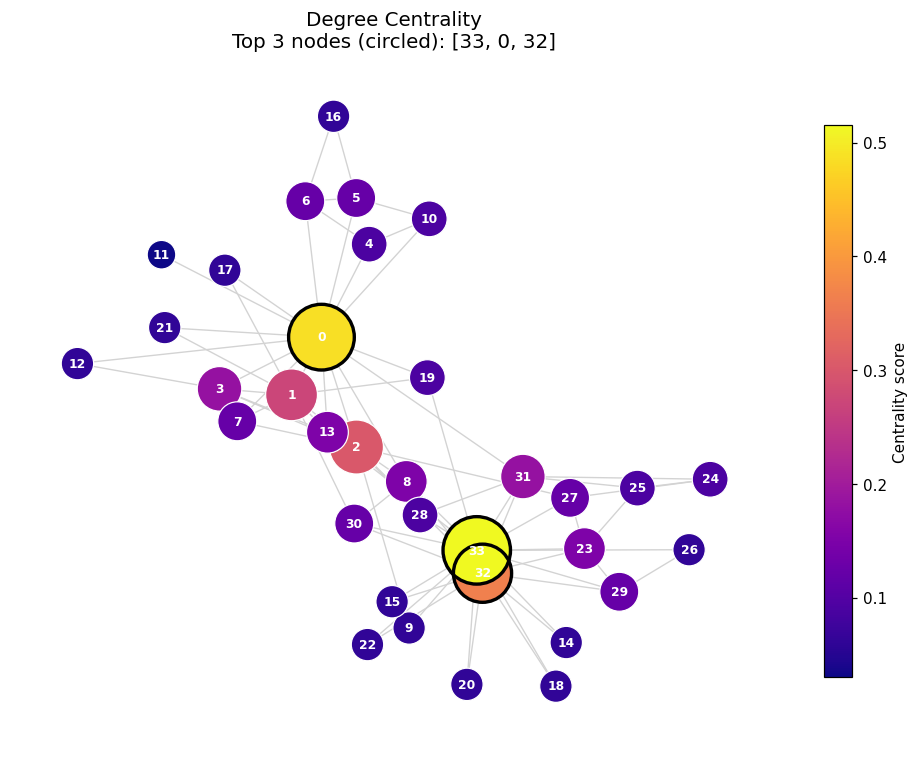

In [9]:
# One fixed layout so every graph is comparable
pos = nx.spring_layout(G, seed=42)

centralities = {
    "Degree Centrality": degree,
    "Closeness Centrality": closeness,
    "Betweenness Centrality": betweenness,
    "Eigenvector Centrality": eigenvector,
    "PageRank": pagerank,
}

def draw_centrality_graph(title, scores, fname=None, top_k=3):
    """Draw the network with node colour/size proportional to the centrality score."""
    nodes = list(G.nodes())
    values = [scores[n] for n in nodes]
    vmax = max(values)

    fig, ax = plt.subplots(figsize=(9, 7))
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="lightgray", width=0.9)
    nc = nx.draw_networkx_nodes(
        G, pos, ax=ax, nodelist=nodes, node_color=values,
        node_size=[250 + 1700 * v / vmax for v in values],
        cmap=plt.cm.plasma, edgecolors="white", linewidths=0.8
    )
    # Circle the top-k nodes in black
    top_nodes = sorted(scores, key=scores.get, reverse=True)[:top_k]
    nx.draw_networkx_nodes(
        G, pos, ax=ax, nodelist=top_nodes, node_color="none",
        node_size=[250 + 1700 * scores[n] / vmax for n in top_nodes],
        edgecolors="black", linewidths=2.2
    )
    if G.number_of_nodes() <= 100:
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, font_color="white", font_weight="bold")
    cbar = plt.colorbar(nc, ax=ax, shrink=0.8)
    cbar.set_label("Centrality score")
    ax.set_title(f"{title}\nTop {top_k} nodes (circled): {top_nodes}", fontsize=13)
    ax.axis("off")
    plt.tight_layout()
    if fname:
        plt.savefig(f"figures/{fname}.png", dpi=150, bbox_inches="tight")
    plt.show()

draw_centrality_graph("Degree Centrality", degree, "1_degree_network")

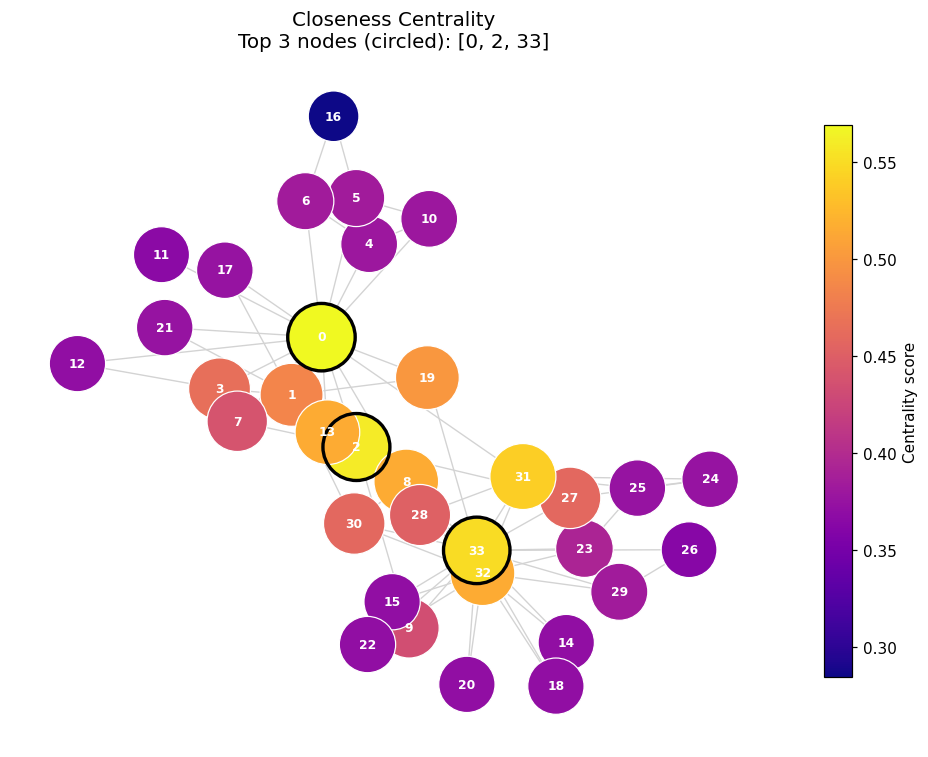

In [10]:
draw_centrality_graph("Closeness Centrality", closeness, "2_closeness_network")

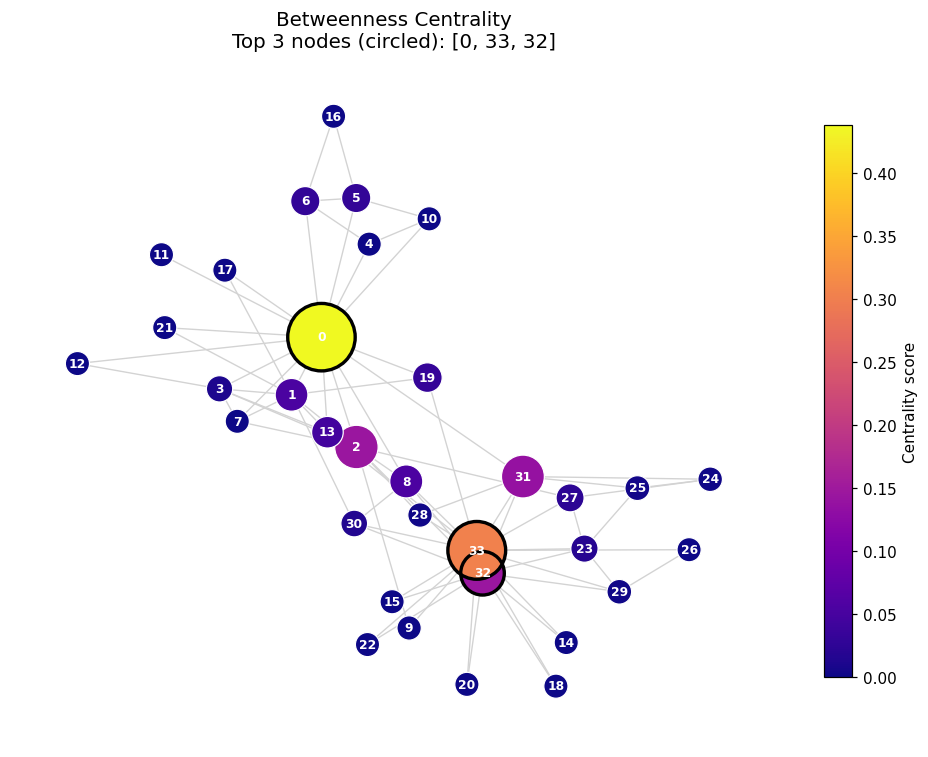

In [11]:
draw_centrality_graph("Betweenness Centrality", betweenness, "3_betweenness_network")

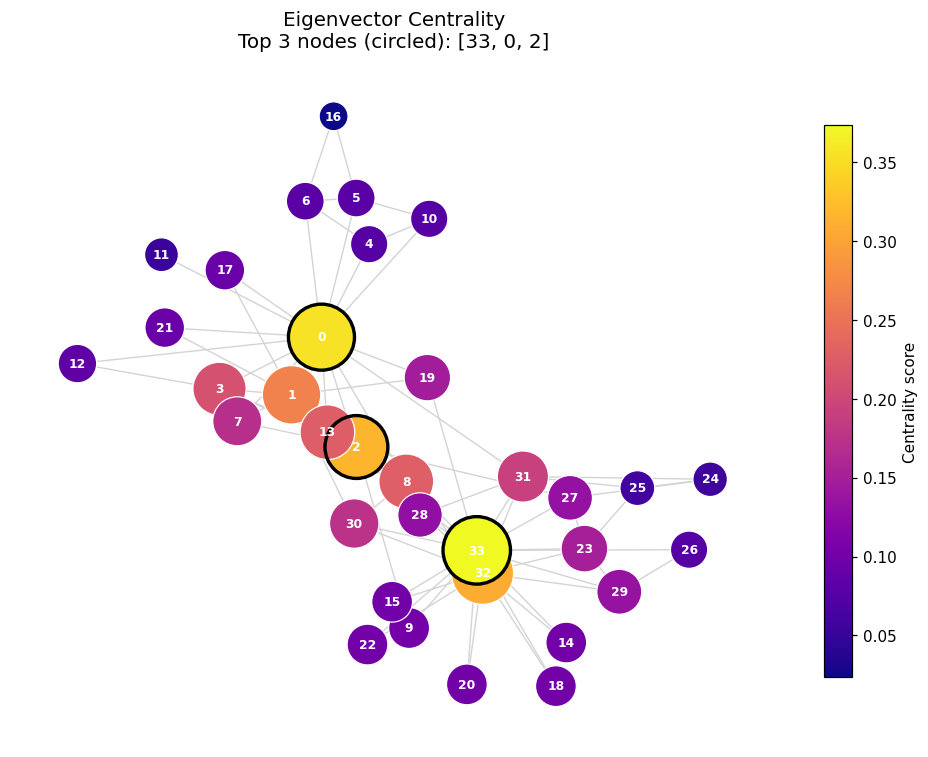

In [12]:
draw_centrality_graph("Eigenvector Centrality", eigenvector, "4_eigenvector_network")

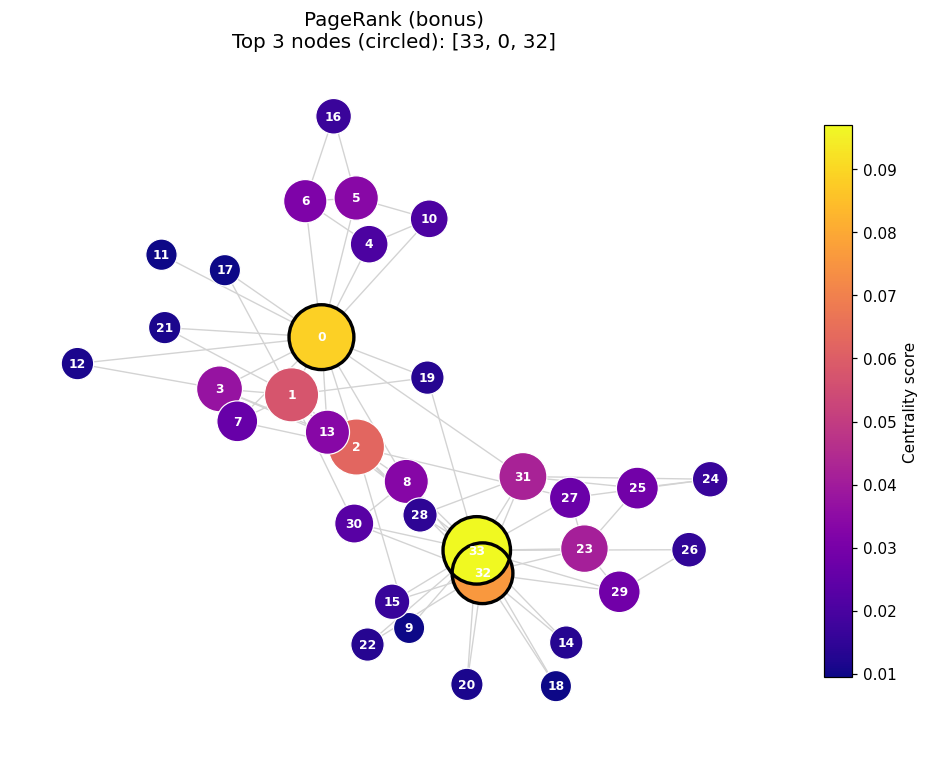

In [13]:
draw_centrality_graph("PageRank (bonus)", pagerank, "5_pagerank_network")

## 5. Bar chart of the top 10 nodes for every centrality

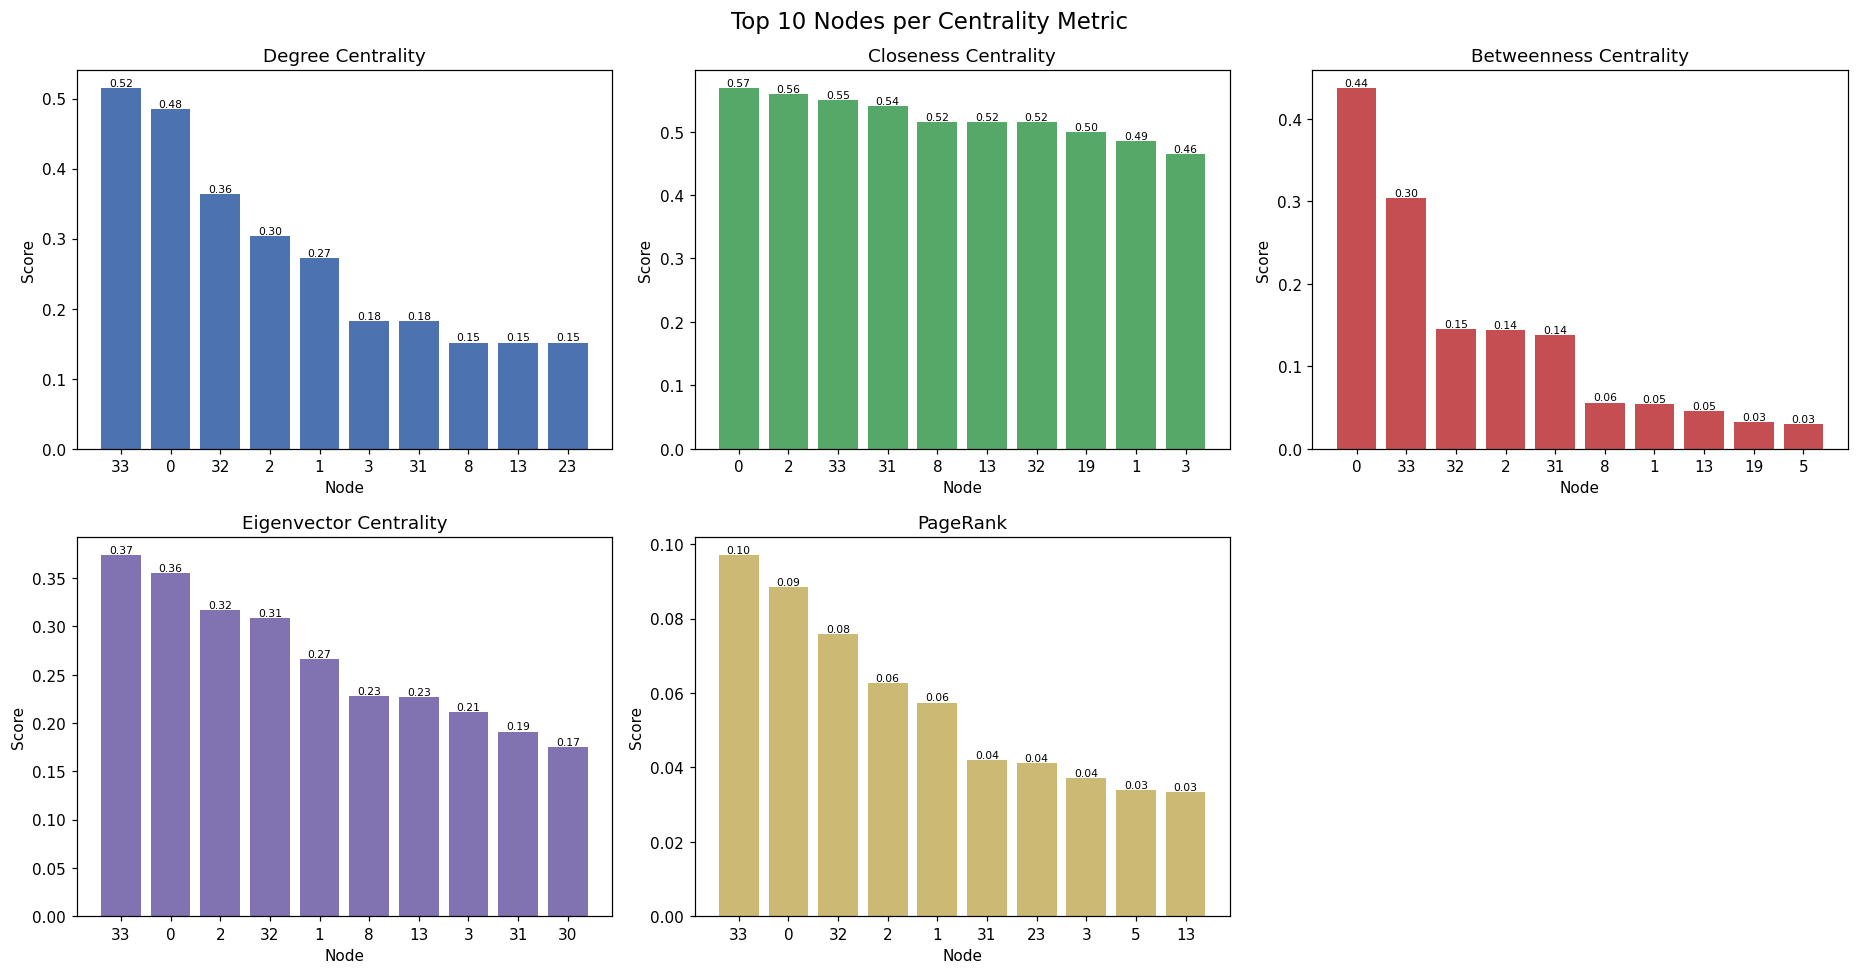

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]

for ax, color, (title, scores) in zip(axes.flatten(), colors, centralities.items()):
    top10 = sorted(scores.items(), key=lambda x: x[1], reverse=True)[:10]
    labels = [str(n) for n, _ in top10]
    vals = [v for _, v in top10]
    ax.bar(labels, vals, color=color)
    ax.set_title(title)
    ax.set_xlabel("Node")
    ax.set_ylabel("Score")
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=7)

axes.flatten()[-1].axis("off")   # 6th panel unused
plt.suptitle("Top 10 Nodes per Centrality Metric", fontsize=15)
plt.tight_layout()
plt.savefig("figures/6_top10_bar_charts.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. All four core metrics side by side (2 x 2 overview)

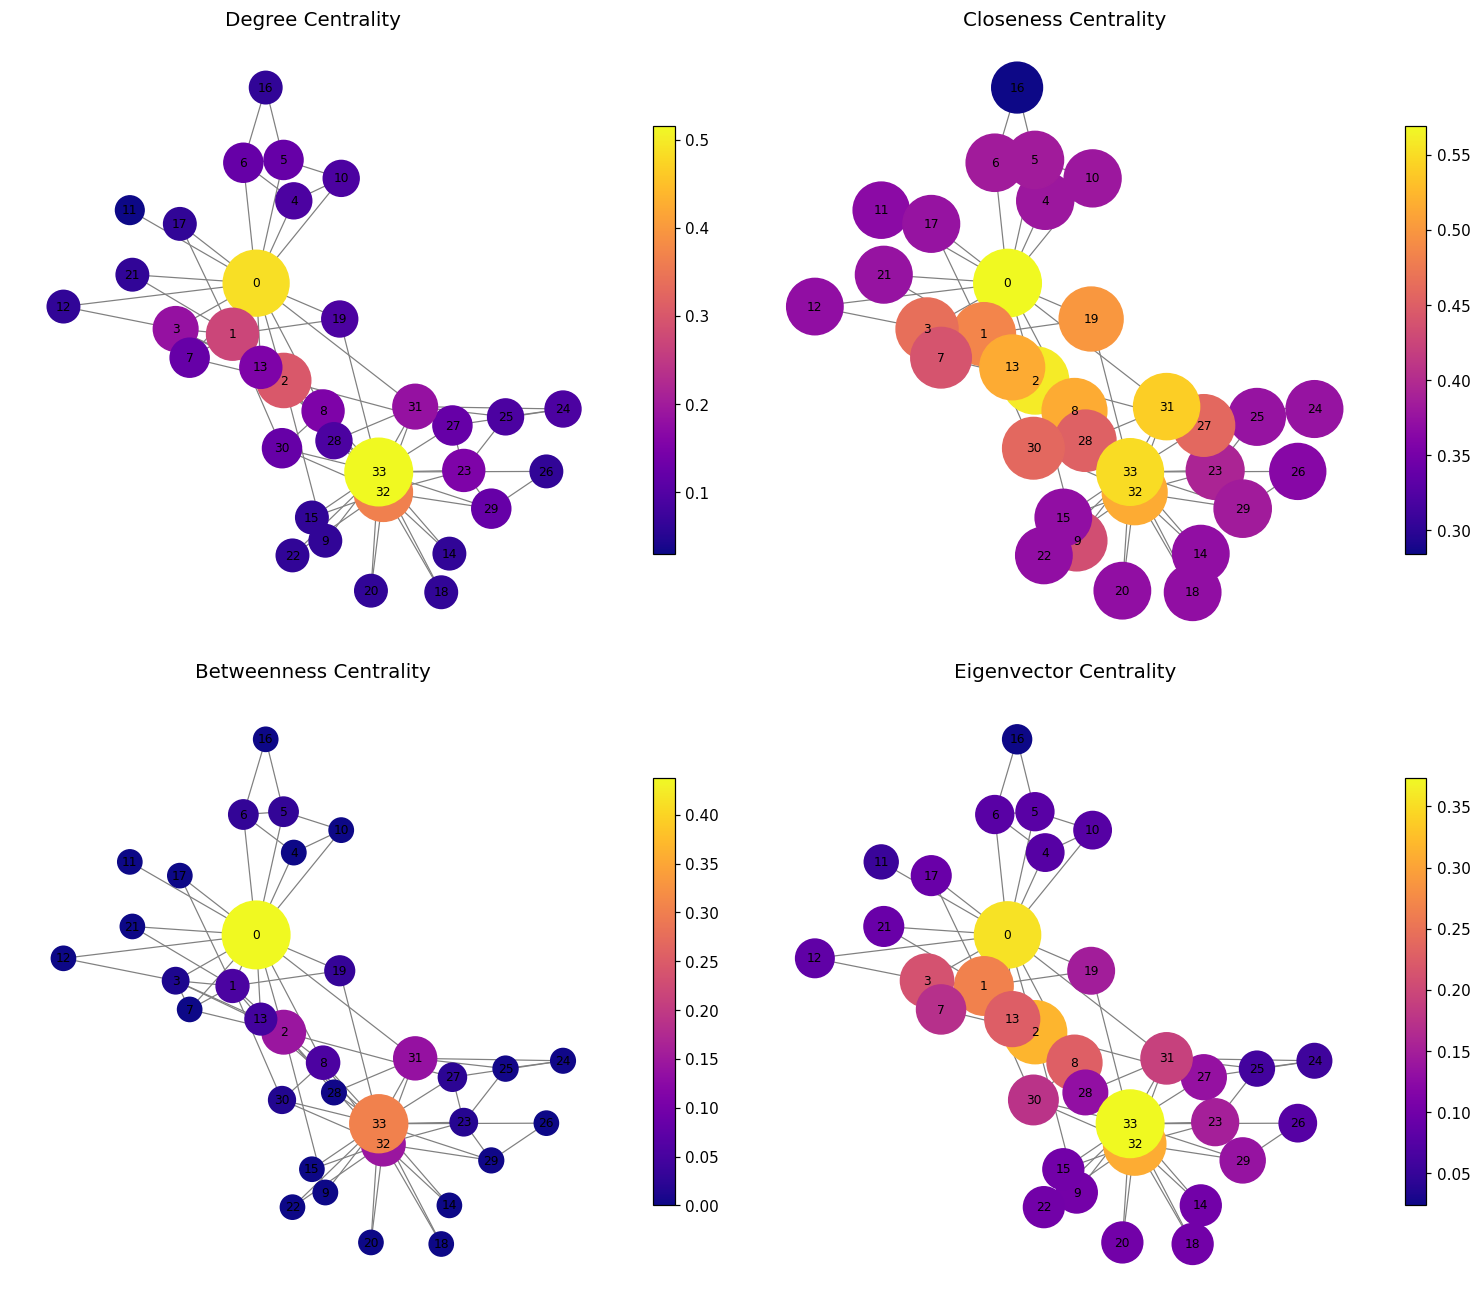

In [15]:
core = {k: v for k, v in centralities.items() if k != "PageRank"}

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, (title, scores) in zip(axes.flatten(), core.items()):
    values = [scores[n] for n in G.nodes()]
    vmax = max(values)
    nc = nx.draw_networkx_nodes(
        G, pos, ax=ax, node_color=values,
        node_size=[250 + 1700 * v / vmax for v in values],
        cmap=plt.cm.plasma
    )
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="gray", width=0.8)
    if G.number_of_nodes() <= 100:
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)
    plt.colorbar(nc, ax=ax, shrink=0.7)
    ax.set_title(title, fontsize=13)
    ax.axis("off")

plt.tight_layout()
plt.savefig("figures/7_overview_2x2.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Comparing metrics: heatmap and correlation

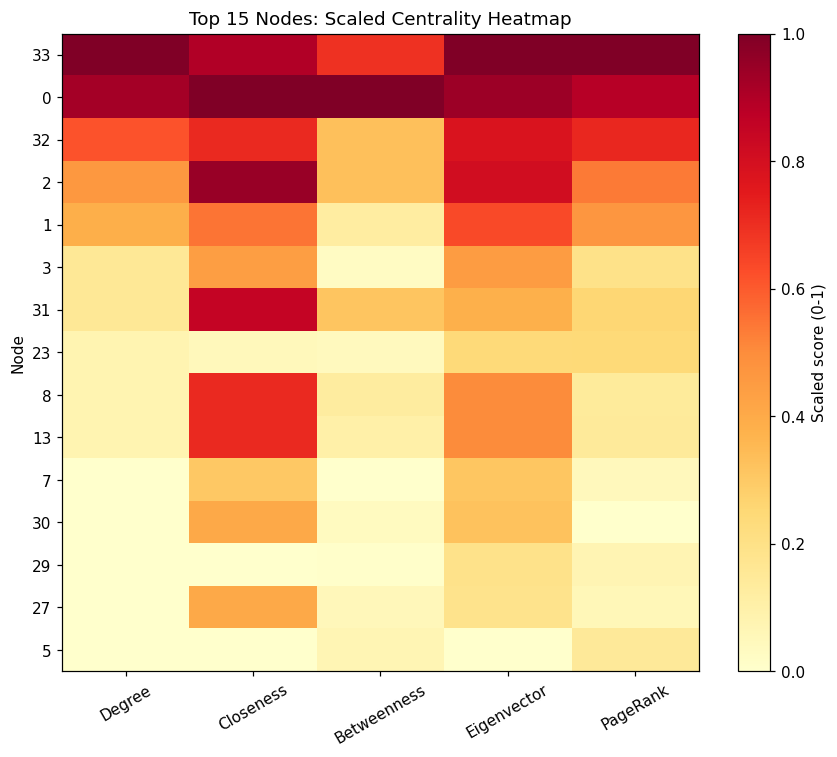

             Degree  Closeness  Betweenness  Eigenvector  PageRank
Degree        1.000      0.772        0.915        0.917     0.982
Closeness     0.772      1.000        0.718        0.905     0.737
Betweenness   0.915      0.718        1.000        0.803     0.872
Eigenvector   0.917      0.905        0.803        1.000     0.887
PageRank      0.982      0.737        0.872        0.887     1.000


In [16]:
top15 = centrality_df.head(15).set_index("Node")[metrics]
# Scale each metric to 0-1 so columns are comparable in one heatmap
scaled = (top15 - top15.min()) / (top15.max() - top15.min())

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(scaled.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(metrics)))
ax.set_xticklabels(metrics, rotation=30)
ax.set_yticks(range(len(scaled)))
ax.set_yticklabels(scaled.index)
ax.set_ylabel("Node")
ax.set_title("Top 15 Nodes: Scaled Centrality Heatmap")
plt.colorbar(im, ax=ax, label="Scaled score (0-1)")
plt.tight_layout()
plt.savefig("figures/8_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# How similar are the metrics to each other?
print(centrality_df[metrics].corr().round(3))

## 8. Key insight (Karate Club): Node 0 (Mr. Hi, the instructor) vs Node 33 (the Officer, the president)

The club split into two factions after a dispute between these two leaders.

In [17]:
if IS_KARATE:
    print(
        centrality_df[centrality_df["Node"].isin([0, 33])]
        .sort_values("Node").round(4).to_string(index=False)
    )
    print("\nClub memberships:")
    print("Node 0  ->", G.nodes[0]["club"])
    print("Node 33 ->", G.nodes[33]["club"])
else:
    print("Top 5 most influential nodes per metric:")
    for m in metrics:
        print(m, "->", centrality_df.nlargest(5, m)["Node"].tolist())

 Node  Degree  Closeness  Betweenness  Eigenvector  PageRank
    0  0.4848      0.569       0.4376       0.3555    0.0885
   33  0.5152      0.550       0.3041       0.3734    0.0970

Club memberships:
Node 0  -> Mr. Hi
Node 33 -> Officer


## 9. Conclusions

* **Node 33 (Officer)** has the highest **degree** (0.5152) and **eigenvector** (0.3734) scores: he has the most friends and they are well-connected too.
* **Node 0 (Mr. Hi)** has the highest **closeness** (0.5690) and **betweenness** (0.4376): he reaches everyone fastest and is the main bridge between the two groups.
* **Nodes 32 and 2** also rank high on several metrics and act as secondary hubs / bridges.
* The two leaders dominate every ranking, which matches the real history: the club split into two factions around exactly these two people.